# 01 Validation — SIR baseline (no behaviour)
Checks: beta=0 no spread, gamma=1 fast recovery, determinism, mean-field sanity.

0.0 0.033 peak 0.033 dur 53
0.06 0.98 peak 0.383 dur 126
0.12 1.0 peak 0.65 dur 118
0.2 1.0 peak 0.747 dur 118


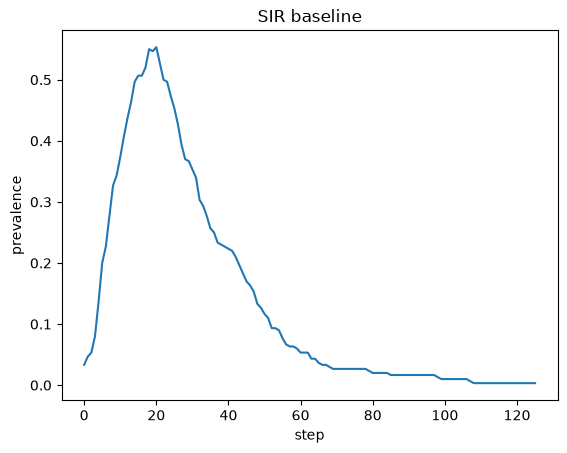

In [2]:
import sys
from pathlib import Path

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent

if not (project_root / "src").is_dir():
    raise RuntimeError("src can't find")

sys.path.insert(0, str(project_root))
from src.simulation import SimParams, run_coupled
import matplotlib.pyplot as plt

for beta in [0.0, 0.06, 0.12, 0.2]:
    out = run_coupled(SimParams(topology='ws', n=300, seed=0, beta=beta, rule='none'))
    print(beta, round(out['final_size'],3), 'peak', round(out['peak'],3), 'dur', out['duration'])

out = run_coupled(SimParams(topology='ws', n=300, seed=1, beta=0.12, rule='none'))
plt.plot(out['prev_series']); plt.xlabel('step'); plt.ylabel('prevalence'); plt.title('SIR baseline'); plt.show()